# 09 Simple Multimodal Model (Early Fusion)

**What this model is.** It joins each image's CLIP vector and its caption's CLIP vector into one long input, then trains one classifier on both at once. This is called *early fusion*, because image and caption are combined *before* the model makes a decision. The baseline instead combines two separate models' answers *after* each has decided. Because it sees both together, it can learn whether a caption fits its photo.

**Question:** does a small neural classifier learn useful image–caption relationships from frozen CLIP embeddings, and do explicit comparison features help?

`10` is a hybrid stack: it combines classifier scores, handcrafted features and cross-modal similarities through gradient boosting. It already contains a linear image/caption pair classifier. This notebook compares a **neural joint classifier** with matched linear baselines; it does not claim feature-level fusion is new.

| Experiment | Inputs | Dimensions |
|---|---|---:|
| LR concat | Image + caption vectors, concatenated | 1,536 |
| MLP concat | Same joined vectors | 1,536 |
| LR comparisons | Joined vectors + element-wise product + absolute difference | 3,072 |
| MLP comparisons | Same explicit comparison inputs | 3,072 |

Each model predicts `image_fake` and `text_fake`. Overall `is_fake`: A pair counts as genuine only if both its photo and its caption appear genuine: $P(\text{fake}) = 1 - (1 - p_{\text{image}})(1 - p_{\text{text}})$ (see `11`, *Combining Image and Caption Scores*). No direct overall-fake head is added.

**No new neural feature extraction, model download or test evaluation.** Section 9 scores the test rows with the frozen final model for `11_model_comparison`, without reading any test label. Use the full existing `02` training sample and full validation set, not the smaller emotion sample from `08`. CLIP encoders remain frozen. The saved outputs are from the latest full run. Run from `notebooks/` using the project `.venv` kernel; prerequisites are matching `02` and `05` exports. `10` need not be rerun to train these models.

## 1. Setup and Fixed Settings

Train only small heads on existing arrays. Epoch time depends on hardware; the notebook prints device, progress and elapsed time. Set `DEVICE="cpu"` if an accelerator is unsupported; lower batch size if memory is limited, recording the change as a new configuration.

The primary seed is fixed at 4012. Seeds 4013/4014 measure neural training variability and are not candidates from which to select the most flattering result. All use the same internal article split. No class weighting or external validation tuning is added.

In [1]:
import sys
import json
import time
import gc
from pathlib import Path
from datetime import datetime, timezone
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import sklearn
from sklearn.preprocessing import StandardScaler
from IPython.display import display, Markdown

PROJECT_ROOT = Path("..").resolve()
assert (PROJECT_ROOT / "src/early_fusion.py").exists(), "Run this notebook from notebooks/"
sys.path.insert(0, str(PROJECT_ROOT))
import importlib
import src.early_fusion as fusion
importlib.reload(fusion)
from src.evaluation import binary_metrics, detection_rate_by_type

PRIMARY_SEED = 4012
NEURAL_SEEDS = [4012, 4013, 4014]
MAX_EPOCHS = 30
BOOTSTRAPS = 500
DEVICE = fusion.best_device()
TRAINING = fusion.DEFAULT_TRAINING.copy()
MODES = ["concat", "comparisons"]
PROCESSED = PROJECT_ROOT / "data/processed"
FEATURES = PROJECT_ROOT / "data/features"
print(f"Device: {DEVICE}; max epochs: {MAX_EPOCHS}; batch size: {TRAINING['batch_size']}")
print("No image decoding, neural encoding or emotion extraction is required.")

Device: mps; max epochs: 30; batch size: 256
No image decoding, neural encoding or emotion extraction is required.


## 2. Load and Validate Pair-Aligned Embeddings

Concatenation puts both vectors side by side; it does not calculate similarity. Product and absolute difference expose dimension-wise interactions. These are features, not calibrated inconsistency scores.

Require exact unique row-ID coverage, identical feature dimension order across modalities/splits, finite values, binary targets, consistent overall labels and disjoint article IDs. Predictor columns are selected explicitly. IDs and manipulation types are used only for splitting/evaluation. No test file is read.

In [2]:
input_paths = {}
labels, vectors = {}, {}
ordered_columns = None
required_metadata = ["row_id", "id", "fake_cls", "image_fake", "text_fake", "is_fake"]
for split in ["train_sample", "validation"]:
    metadata_path = PROCESSED / f"{split}.parquet"
    embedding_path = FEATURES / f"clip_emb_{split}.parquet"
    labels[split] = pd.read_parquet(metadata_path, columns=required_metadata).reset_index(drop=True)
    embeddings = pd.read_parquet(embedding_path)
    image, text, columns = fusion.align_embeddings(labels[split], embeddings, ordered_columns)
    ordered_columns = columns
    assert image.shape[1] == text.shape[1] == 768, "Expected 05's CLIP ViT-L/14 exports"
    vectors[split] = image, text
    input_paths.update({str(p.relative_to(PROJECT_ROOT)): fusion.file_hash(p) for p in [metadata_path, embedding_path]})
    del embeddings
train, val = labels["train_sample"], labels["validation"]
assert not (set(train.id) & set(val.id)), "Article overlap across training and validation"
assert not (set(train.row_id) & set(val.row_id))
fit_idx, holdout_idx = fusion.grouped_holdout(train, PRIMARY_SEED)
y_train = train[list(fusion.TARGETS)].to_numpy(dtype=np.float32)
display(pd.DataFrame([{"split": name, "rows": len(frame), "articles": frame.id.nunique(),
    "genuine": int(frame.is_fake.eq(0).sum()), "manipulated": int(frame.is_fake.eq(1).sum())}
    for name, frame in labels.items()]))
print(f"Internal split: {len(fit_idx):,} fit rows, {len(holdout_idx):,} holdout rows; articles stay together.")
print("All four experiments use the same rows. Expected existing sizes: 49,943 train / 22,126 validation.")

,split,rows,articles,genuine,manipulated
0,train_sample,49943,18100,16848,33095
1,validation,22126,7975,7473,14653


Internal split: 39,976 fit rows, 9,967 holdout rows; articles stay together.
All four experiments use the same rows. Expected existing sizes: 49,943 train / 22,126 validation.


## 3. Run Configuration and Local Caches

Each execution creates a separate cache directory under `data/interim/early_fusion_09/`, which is already git-ignored. Configuration, split membership, scalers, model checkpoints, histories and prediction arrays are kept there for reuse. Evaluation tables are displayed in the notebook, not exported as CSV files. Rerunning setup creates a new directory and preserves older runs. No existing `10`/`08` results are overwritten.

In [3]:
notebook_path = PROJECT_ROOT / "notebooks/09_multimodal_early_fusion.ipynb"
notebook_sources = [(c["cell_type"], "".join(c["source"])) for c in json.loads(notebook_path.read_text())["cells"]]
near_dup_path = PROJECT_ROOT / "data/interim/clip/near_duplicates.parquet"
reference_path = PROJECT_ROOT / "results/predictions/multimodal_stacking_validation.parquet"
configuration = {"primary_seed": PRIMARY_SEED, "neural_seeds": NEURAL_SEEDS, "max_epochs": MAX_EPOCHS,
    "training": TRAINING, "internal_holdout_fraction": .2, "internal_split_seed": PRIMARY_SEED,
    "linear_C_candidates": [.001,.01,.1,1.], "bootstrap_resamples": BOOTSTRAPS,
    "architecture": "input-256-ReLU-Dropout(.2)-64-ReLU-Dropout(.2)-2 logits",
    "targets": list(fusion.TARGETS), "overall_rule": "noisy-OR", "test_evaluated": False,
    "input_fingerprints": input_paths, "ordered_features": {mode: fusion.feature_names(ordered_columns, mode) for mode in MODES},
    "helper_sha256": fusion.file_hash(PROJECT_ROOT / "src/early_fusion.py"),
    "evaluation_sha256": fusion.file_hash(PROJECT_ROOT / "src/evaluation.py"),
    "notebook_source_fingerprint": fusion.fingerprint(notebook_sources),
    "near_duplicate_sha256": fusion.file_hash(near_dup_path) if near_dup_path.exists() else None,
    "saved_05_sha256": fusion.file_hash(reference_path) if reference_path.exists() else None,
    "device": DEVICE, "versions": {"numpy": np.__version__, "pandas": pd.__version__,
        "torch": str(torch.__version__), "sklearn": sklearn.__version__, "joblib": joblib.__version__},
    "determinism": "seeded; deterministic algorithms requested with warnings; cross-device equality not guaranteed"}
run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ") + "_" + fusion.fingerprint(configuration)[:12]
RUN_DIR = PROJECT_ROOT / "data/interim/early_fusion_09" / run_id
RUN_DIR.mkdir(parents=True, exist_ok=False)
fusion.write_json(RUN_DIR / "configuration.json", {**configuration, "status": "incomplete"})
manifest = train[["row_id", "id"]].copy()
manifest["internal_role"] = "fit"
manifest.loc[holdout_idx, "internal_role"] = "holdout"
manifest.to_parquet(RUN_DIR / "training_membership.parquet", index=False)
val[["row_id", "id"]].to_parquet(RUN_DIR / "validation_membership.parquet", index=False)
print(f"Artifacts: {RUN_DIR.relative_to(PROJECT_ROOT)}")
predictions, histories, selections, timings = {}, {}, [], []

Artifacts: data/interim/early_fusion_09/20261119T131901485438Z_4bb038b9105a


## 4. Matched Logistic Regression Baselines

For each representation, fit the scaler on internal fit rows only while selecting each target's `C` by internal holdout AUC. Refit the scaler and the chosen heads on the full training sample afterward. Official validation is scored only after fitting. This controls for feature engineering independently of the neural learner.

In [4]:
for mode in MODES:
    started = time.perf_counter()
    x = fusion.joint_features(*vectors["train_sample"], mode)
    xv = fusion.joint_features(*vectors["validation"], mode)
    scaler, heads, selection = fusion.fit_linear(x, y_train, fit_idx, holdout_idx)
    name = f"LR {mode}"
    predictions[name] = fusion.predict_linear(scaler, heads, xv)
    selection["mode"] = mode
    selections.append(selection)
    joblib.dump({"scaler": scaler, "heads": heads, "mode": mode,
                 "target_order": fusion.TARGETS, "feature_names": configuration["ordered_features"][mode]}, RUN_DIR / f"lr_{mode}.joblib")
    timings.append({"experiment": name, "seconds": time.perf_counter()-started})
    print(f"{name} finished in {timings[-1]['seconds']:.1f}s", flush=True)
    del x, xv, scaler, heads
    gc.collect()
display(pd.concat(selections, ignore_index=True))

LR concat finished in 38.3s


LR comparisons finished in 78.0s


,target,C,internal_AUC,mode
0,image_fake,0.001,0.800462,concat
1,image_fake,0.010,0.801997,concat
2,image_fake,0.100,0.804617,concat
3,image_fake,1.000,0.807335,concat
4,text_fake,0.001,0.747509,concat
5,text_fake,0.010,0.746433,concat
6,text_fake,0.100,0.747668,concat
7,text_fake,1.000,0.749051,concat
8,image_fake,0.001,0.794685,comparisons
9,image_fake,0.010,0.793481,comparisons


## 5. Neural Joint Classifiers

Two heads share the same hidden layers. Training minimizes mean binary cross-entropy equally across image/text targets. For each seed: fit an internal scaler, select the epoch count using **internal holdout BCE**, then initialize a fresh model/scaler and train on **all training rows** for that many epochs.

The official validation set is not an early-stopping set. Primary comparisons use seed 4012; repeated seeds quantify variability. No model weights or epochs are selected from official validation scores. Neural training is still an experiment: it is not guaranteed to outperform the linear baselines or `10`.


MLP concat seed 4012: internal epoch selection


epoch 01/30: train_loss=0.5455, elapsed_seconds=1.5171, holdout_loss=0.4997


epoch 02/30: train_loss=0.4770, elapsed_seconds=1.9672, holdout_loss=0.4795


epoch 03/30: train_loss=0.4343, elapsed_seconds=2.4104, holdout_loss=0.4702


epoch 04/30: train_loss=0.3999, elapsed_seconds=2.8576, holdout_loss=0.4646


epoch 05/30: train_loss=0.3696, elapsed_seconds=3.3009, holdout_loss=0.4699


... (70 outputs left out)

epoch 07/30: train_loss=0.2319, elapsed_seconds=3.9679, holdout_loss=0.5771


MLP comparisons seed 4014: refit all training rows for 2 epochs


epoch 01/2: train_loss=0.4762, elapsed_seconds=1.4493


epoch 02/2: train_loss=0.3989, elapsed_seconds=2.8357


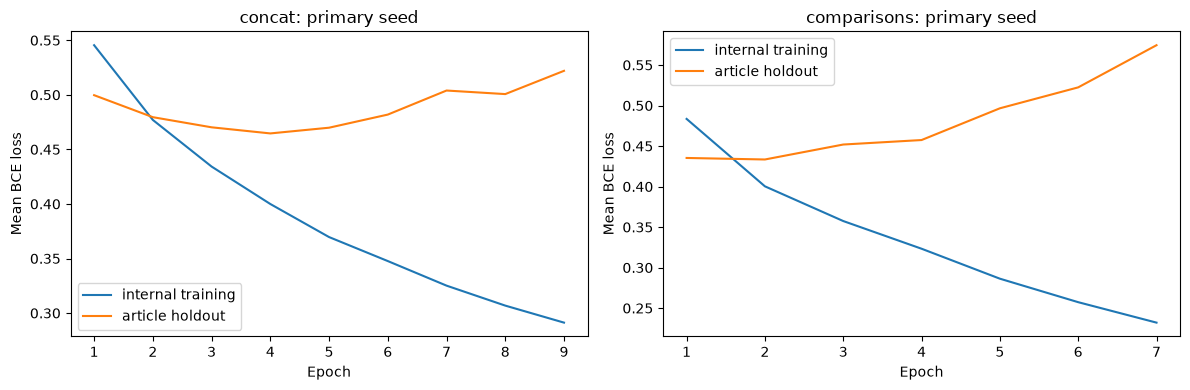

In [5]:
for mode in MODES:
    x = fusion.joint_features(*vectors["train_sample"], mode)
    xv = fusion.joint_features(*vectors["validation"], mode)
    inner_scaler = StandardScaler().fit(x[fit_idx])
    xf = inner_scaler.transform(x[fit_idx]).astype(np.float32)
    xh = inner_scaler.transform(x[holdout_idx]).astype(np.float32)
    final_scaler = StandardScaler().fit(x)
    x_full = final_scaler.transform(x).astype(np.float32)
    xv_scaled = final_scaler.transform(xv).astype(np.float32)
    joblib.dump(final_scaler, RUN_DIR / f"mlp_{mode}_scaler.joblib")
    for seed in NEURAL_SEEDS:
        started = time.perf_counter()
        name = f"MLP {mode} seed {seed}"
        print(f"\n{name}: internal epoch selection", flush=True)
        selected_model, selection_history, best_epoch = fusion.train_network(
            xf, y_train[fit_idx], epochs=MAX_EPOCHS, seed=seed, device=DEVICE,
            holdout=(xh, y_train[holdout_idx]), **TRAINING)
        torch.save({"state_dict": {k:v.detach().cpu() for k,v in selected_model.state_dict().items()},
                    "input_dim": x.shape[1], "best_epoch": best_epoch, "seed": seed},
                   RUN_DIR / f"mlp_{mode}_{seed}_internal_best.pt")
        del selected_model
        print(f"{name}: refit all training rows for {best_epoch} epochs", flush=True)
        model, refit_history, _ = fusion.train_network(x_full, y_train, epochs=best_epoch,
            seed=seed, device=DEVICE, **TRAINING)
        predictions[name] = fusion.predict_network(model, xv_scaled, DEVICE, TRAINING["batch_size"])
        checkpoint = {"state_dict": {k:v.detach().cpu() for k,v in model.state_dict().items()},
                      "input_dim": x.shape[1], "mode": mode, "seed": seed, "epochs": best_epoch,
                      "target_order": list(fusion.TARGETS), "dropout": .2}
        checkpoint_path = RUN_DIR / f"mlp_{mode}_{seed}.pt"
        torch.save(checkpoint, checkpoint_path)
        # Reload the primary-seed checkpoint and verify validation predictions in batches.
        if seed == PRIMARY_SEED:
            saved = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
            reloaded = fusion.FusionMLP(saved["input_dim"]).to(DEVICE)
            reloaded.load_state_dict(saved["state_dict"])
            recovered = fusion.predict_network(reloaded, xv_scaled[:256], DEVICE)
            assert np.allclose(recovered, predictions[name][:256], atol=1e-6)
            del reloaded
        histories[name] = selection_history
        selection_history.to_parquet(RUN_DIR / f"mlp_{mode}_{seed}_selection.parquet", index=False)
        refit_history.to_parquet(RUN_DIR / f"mlp_{mode}_{seed}_refit.parquet", index=False)
        timings.append({"experiment": name, "seconds": time.perf_counter()-started, "selected_epochs": best_epoch})
        del model
        gc.collect()
        if DEVICE == "cuda": torch.cuda.empty_cache()
        elif DEVICE == "mps": torch.mps.empty_cache()
    del x, xv, xf, xh, x_full, xv_scaled, inner_scaler, final_scaler
    gc.collect()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, mode in zip(axes, MODES):
    h = histories[f"MLP {mode} seed {PRIMARY_SEED}"]
    ax.plot(h.epoch, h.train_loss, label="internal training")
    ax.plot(h.epoch, h.holdout_loss, label="article holdout")
    ax.set(title=f"{mode}: primary seed", xlabel="Epoch", ylabel="Mean BCE loss")
    ax.legend()
plt.tight_layout()
plt.show()

## 6. Validation Comparisons

Two views: F1-selected thresholds and thresholds permitting **at most 1% of genuine validation pairs** to be flagged. Each model/target has its own threshold; do not compare recall at arbitrary equal score cutoffs. Thresholds are selected and assessed on validation, so operating-point estimates are exploratory.

AUC measures ranking, not accuracy. A model can improve AUC yet worsen strict recall. The saved `10` predictions are a historical reference with different inputs/architecture, not a controlled test of fusion alone. Exact current validation row coverage is mandatory; provenance of its original training features is not reconstructed here.

In [6]:
reference, reference_status = fusion.saved_reference(reference_path, val)
print(reference_status)
if reference is not None:
    predictions["Saved 10 reference"] = reference
metrics = fusion.validation_tables(val, predictions)
primary_names = ["LR concat", "LR comparisons", f"MLP concat seed {PRIMARY_SEED}", f"MLP comparisons seed {PRIMARY_SEED}"]
if reference is not None: primary_names += ["Saved 10 reference"]
primary = metrics[metrics.experiment.isin(primary_names)]
summary = primary[(primary.target == "is_fake") & (primary.operating_point == "F1")][["experiment","AUC","PR-AUC","EER","F1","genuine_FPR"]]
strict = primary[(primary.target == "is_fake") & (primary.operating_point == "FPR1")][["experiment","Recall","genuine_FPR"]]
summary = summary.merge(strict, on="experiment", suffixes=("_at_F1", "_at_FPR1"), validate="one_to_one")
display(Markdown("**Overall detection: primary comparison**"))
display(summary.round(4))
display(Markdown("**All three targets, primary models, at the F1-selected operating point**"))
display(primary[primary.operating_point == "F1"].round(4))

seed_rows = metrics[metrics.experiment.str.startswith("MLP")].copy()
seed_rows["architecture"] = seed_rows.experiment.str.replace(r" seed \d+$", "", regex=True)
variability = seed_rows.groupby(["architecture","target","operating_point"])[["AUC","PR-AUC","F1","Recall"]].agg(["mean","std"])
display(Markdown("**Neural seed variability: mean and standard deviation, not a best-seed selection**"))
display(variability.round(4))

Saved 10 reference aligned. Historical feature/model provenance is not re-established.


**Overall detection: primary comparison**

,experiment,AUC,PR-AUC,EER,F1,genuine_FPR_at_F1,Recall,genuine_FPR_at_FPR1
0,LR concat,0.7627,0.8680,0.3116,0.8094,0.8457,0.1884,0.0099
1,LR comparisons,0.8124,0.9011,0.2703,0.8218,0.5810,0.2851,0.0099
2,MLP concat seed 4012,0.8037,0.8957,0.2799,0.8219,0.6242,0.2754,0.0099
3,MLP comparisons seed 4012,0.8175,0.9062,0.2729,0.8243,0.6625,0.3448,0.0099
4,Saved 10 reference,0.8721,0.9350,0.2213,0.8499,0.4779,0.4089,0.0099


**All three targets, primary models, at the F1-selected operating point**

,experiment,target,operating_point,AUC,PR-AUC,EER,ACC,Precision,Recall,F1,threshold,genuine_FPR
0,LR concat,image_fake,F1,0.8008,0.8337,0.2816,0.6988,0.6689,0.8743,0.7579,0.3409,0.5181
2,LR concat,text_fake,F1,0.7353,0.5238,0.3296,0.6764,0.4287,0.6630,0.5207,0.2605,0.3324
4,LR concat,is_fake,F1,0.7627,0.8680,0.3116,0.6965,0.6929,0.9730,0.8094,0.2770,0.8457
6,LR comparisons,image_fake,F1,0.7939,0.8271,0.2883,0.6980,0.6707,0.8643,0.7553,0.3308,0.5045
8,LR comparisons,text_fake,F1,0.8861,0.8077,0.1968,0.8553,0.7509,0.6798,0.7136,0.4309,0.0780
10,LR comparisons,is_fake,F1,0.8124,0.9011,0.2703,0.7403,0.7532,0.9041,0.8218,0.3929,0.5810
12,MLP concat seed 4012,image_fake,F1,0.8102,0.8453,0.2819,0.7079,0.6792,0.8689,0.7624,0.4035,0.5010
14,MLP concat seed 4012,text_fake,F1,0.8424,0.7197,0.2419,0.8058,0.6289,0.6524,0.6404,0.3829,0.1568
16,MLP concat seed 4012,is_fake,F1,0.8037,0.8957,0.2799,0.7361,0.7429,0.9198,0.8219,0.4563,0.6242
30,MLP comparisons seed 4012,image_fake,F1,0.7970,0.8319,0.2908,0.6883,0.6518,0.9063,0.7583,0.3448,0.5865


**Neural seed variability: mean and standard deviation, not a best-seed selection**

AUC          PR-AUC          \
                                              mean     std    mean     std   
architecture    target     operating_point                                   
MLP comparisons image_fake F1               0.7970  0.0019  0.8329  0.0013   
                           FPR1             0.7970  0.0019  0.8329  0.0013   
                is_fake    F1               0.8183  0.0007  0.9066  0.0005   
                           FPR1             0.8183  0.0007  0.9066  0.0005   
                text_fake  F1               0.8957  0.0016  0.8212  0.0016   
                           FPR1             0.8957  0.0016  0.8212  0.0016   
MLP concat      image_fake F1               0.8087  0.0013  0.8442  0.0009   
                           FPR1             0.8087  0.0013  0.8442  0.0009   
                is_fake    F1               0.8036  0.0005  0.8957  0.0004   
                           FPR1             0.8036  0.0005  0.8957  0.0004   
                text_fake  F1               0.8440  0.0022  0.7217  0.0050   
                           FPR1             0.8440  0.0022  0.7217  0.0050   

                                                F1          Recall          
                                              mean     std    mean     std  
architecture    target     operating_point                                  
MLP comparisons image_fake F1               0.7579  0.0003  0.9152  0.0077  
                           FPR1             0.4015  0.0042  0.2538  0.0034  
                is_fake    F1               0.8248  0.0009  0.9386  0.0053  
                           FPR1             0.5098  0.0030  0.3438  0.0027  
                text_fake  F1               0.7152  0.0030  0.6949  0.0207  
                           FPR1             0.6326  0.0053  0.4769  0.0069  
MLP concat      image_fake F1               0.7614  0.0014  0.8854  0.0252  
                           FPR1             0.4273  0.0053  0.2743  0.0046  
                is_fake    F1               0.8214  0.0012  0.9172  0.0049  
                           FPR1             0.4250  0.0057  0.2713  0.0046  
                text_fake  F1               0.6411  0.0026  0.6530  0.0035  
                           FPR1             0.4055  0.0217  0.2609  0.0180

## 7. Paired Uncertainty and Error Analysis

Resample validation **articles**, preserving related rows and identical draws across models. Percentile intervals for AUC, F1 and strict recall condition on fitted models and **fixed validation-selected thresholds**. They do not correct for multiple comparisons, selection optimism, threshold-estimation uncertainty or training variation. Inspect the repeated-seed table separately.

Primary pairs test nonlinear learning with matched inputs and the contribution of comparison features. A positive gain against `10` is interesting, but input differences mean it cannot be attributed solely to combining image and caption in one model (early fusion).

In [7]:
comparisons = [
    (f"MLP concat seed {PRIMARY_SEED}", "LR concat"),
    (f"MLP comparisons seed {PRIMARY_SEED}", "LR comparisons"),
    (f"MLP comparisons seed {PRIMARY_SEED}", f"MLP concat seed {PRIMARY_SEED}"),
    ("LR comparisons", "LR concat"),
]
if reference is not None:
    comparisons += [(f"MLP {mode} seed {PRIMARY_SEED}", "Saved 10 reference") for mode in MODES]
intervals = fusion.paired_bootstrap(val, predictions, metrics, comparisons, repetitions=BOOTSTRAPS, seed=PRIMARY_SEED)
display(intervals[intervals.target == "is_fake"].round(4))

by_type_rows, robustness_rows = [], []
keep = np.ones(len(val), dtype=bool)
if near_dup_path.exists():
    near = pd.read_parquet(near_dup_path)
    assert {"id", "max_sim_to_train_sample"} <= set(near)
    duplicate_ids = set(near.loc[near.max_sim_to_train_sample >= .95,"id"])
    keep = ~val.id.isin(duplicate_ids).to_numpy()
    print(f"Near-duplicate check excludes {(~keep).sum():,} validation pairs; thresholds remain fixed.")
else:
    print("Near-duplicate table missing: exclusion analysis omitted, not assumed clean.")
for name in primary_names:
    scores = fusion.score_targets(predictions[name])
    for point in ["F1","FPR1"]:
        threshold = float(metrics[(metrics.experiment==name)&(metrics.target=="is_fake")&(metrics.operating_point==point)].iloc[0].threshold)
        table = detection_rate_by_type(val, scores["is_fake"], threshold).reset_index()
        table["experiment"], table["operating_point"] = name, point
        by_type_rows.append(table)
        if near_dup_path.exists():
            for target, score in scores.items():
                if val.loc[keep,target].nunique() != 2: continue
                threshold = float(metrics[(metrics.experiment==name)&(metrics.target==target)&(metrics.operating_point==point)].iloc[0].threshold)
                genuine_keep = keep & val.is_fake.eq(0).to_numpy()
                robustness_rows.append({"experiment":name,"target":target,"operating_point":point,"rows":int(keep.sum()),
                    **binary_metrics(val.loc[keep,target],score[keep],threshold),
                    "genuine_FPR":float((score[genuine_keep]>=threshold).mean()) if genuine_keep.any() else np.nan})
by_type = pd.concat(by_type_rows,ignore_index=True)
robustness = pd.DataFrame(robustness_rows)
display(Markdown("**Overall detection by manipulation type at the strict threshold: orig = false-positive rate; others = recall**"))
display(by_type[by_type.operating_point=="FPR1"].pivot(index="fake_cls",columns="experiment",values="flagged_rate").round(4))
if len(robustness): display(robustness.round(4))

Paired article bootstrap 100/500


Paired article bootstrap 200/500


Paired article bootstrap 300/500


Paired article bootstrap 400/500


Paired article bootstrap 500/500


,experiment,reference,target,metric,difference,CI_low,CI_high,valid_resamples
6,MLP concat seed 4012,LR concat,is_fake,AUC,0.0410,0.0374,0.0442,500
7,MLP concat seed 4012,LR concat,is_fake,F1,0.0126,0.0100,0.0152,500
8,MLP concat seed 4012,LR concat,is_fake,Recall_at_FPR1,0.0870,0.0807,0.0939,500
15,MLP comparisons seed 4012,LR comparisons,is_fake,AUC,0.0051,0.0025,0.0080,500
16,MLP comparisons seed 4012,LR comparisons,is_fake,F1,0.0026,-0.0001,0.0052,500
17,MLP comparisons seed 4012,LR comparisons,is_fake,Recall_at_FPR1,0.0596,0.0542,0.0655,500
24,MLP comparisons seed 4012,MLP concat seed 4012,is_fake,AUC,0.0138,0.0102,0.0174,500
25,MLP comparisons seed 4012,MLP concat seed 4012,is_fake,F1,0.0024,0.0001,0.0050,500
26,MLP comparisons seed 4012,MLP concat seed 4012,is_fake,Recall_at_FPR1,0.0694,0.0627,0.0766,500
33,LR comparisons,LR concat,is_fake,AUC,0.0497,0.0467,0.0529,500


Near-duplicate check excludes 383 validation pairs; thresholds remain fixed.


**Overall detection by manipulation type at the strict threshold: orig = false-positive rate; others = recall**

experiment,LR comparisons,LR concat,MLP comparisons seed 4012,MLP concat seed 4012,Saved 10 reference
fake_cls,,,,,
face_attribute,0.2068,0.2241,0.2448,0.2781,0.3118
face_attribute&text_attribute,0.3101,0.2690,0.3450,0.3758,0.4353
face_attribute&text_swap,0.6328,0.2925,0.7832,0.5207,0.7873
face_swap,0.1972,0.1949,0.1886,0.2120,0.3225
face_swap&text_attribute,0.2683,0.2383,0.2927,0.2964,0.4240
face_swap&text_swap,0.6191,0.2614,0.7309,0.4600,0.7730
orig,0.0099,0.0099,0.0099,0.0099,0.0099
text_attribute,0.0436,0.0291,0.0630,0.0897,0.0461
text_swap,0.3944,0.0333,0.6278,0.2408,0.5634


,experiment,target,operating_point,rows,AUC,PR-AUC,EER,ACC,Precision,Recall,F1,threshold,genuine_FPR
0,LR concat,image_fake,F1,21743,0.8008,0.8332,0.2816,0.6980,0.6673,0.8755,0.7574,0.3409,0.5206
1,LR concat,text_fake,F1,21743,0.7342,0.5230,0.3303,0.6758,0.4292,0.6620,0.5207,0.2605,0.3327
2,LR concat,is_fake,F1,21743,0.7621,0.8677,0.3124,0.6961,0.6926,0.9730,0.8092,0.2770,0.8468
3,LR concat,image_fake,FPR1,21743,0.8008,0.8332,0.2816,0.5745,0.9613,0.2186,0.3562,0.9062,0.0099
4,LR concat,text_fake,FPR1,21743,0.7342,0.5230,0.3303,0.7473,0.7491,0.0754,0.1370,0.7583,0.0099
5,LR concat,is_fake,FPR1,21743,0.7621,0.8677,0.3124,0.4593,0.9735,0.1887,0.3161,0.9347,0.0101
6,LR comparisons,image_fake,F1,21743,0.7937,0.8265,0.2885,0.6970,0.6691,0.8650,0.7545,0.3308,0.5071
7,LR comparisons,text_fake,F1,21743,0.8859,0.8077,0.1968,0.8548,0.7511,0.6796,0.7136,0.4309,0.0782
8,LR comparisons,is_fake,F1,21743,0.8120,0.9009,0.2707,0.7396,0.7525,0.9042,0.8214,0.3929,0.5831
9,LR comparisons,image_fake,FPR1,21743,0.7937,0.8265,0.2885,0.5737,0.9572,0.2179,0.3550,0.9240,0.0101


## 8. Display Findings and Keep Reusable Artifacts

The result tables above stay in the saved notebook outputs. Runtime is displayed below. Reusable validation probabilities, thresholds, configuration and model/scaler artifacts stay under `data/interim/early_fusion_09/`; no evaluation CSV files are written. Keep checkpoints, scalers and their feature specifications together for later inference.

Results remain validation-only. Section 9 exports one model's predictions for `11_model_comparison`; none are fed into `10`. Any later stacking integration needs article-grouped out-of-fold neural scores; these in-sample training models are not suitable training predictors for another stack.

In [8]:
display(Markdown("**Training runtime and selected epochs**"))
display(pd.DataFrame(timings).round(2))

for name,p in predictions.items():
    frame = pd.DataFrame({"row_id":val.row_id.to_numpy(), **{"p_"+k:v for k,v in fusion.score_targets(p).items()}})
    frame.to_parquet(RUN_DIR/f"predictions_{fusion.fingerprint(name)[:12]}.parquet",index=False)
fusion.write_json(RUN_DIR/"prediction_files.json", {name:f"predictions_{fusion.fingerprint(name)[:12]}.parquet" for name in predictions})
fusion.write_json(RUN_DIR/"configuration.json", {**configuration,"status":"complete_validation",
    "reference_status":reference_status,"completed_at_utc":datetime.now(timezone.utc).isoformat(),
    "comparisons":comparisons, "thresholds":metrics[["experiment","target","operating_point","threshold"]].to_dict("records"),
    "runtime":timings, "runtime_seconds":sum(row["seconds"] for row in timings)})
print(f"Reusable artifacts: {RUN_DIR.relative_to(PROJECT_ROOT)}; evaluation tables are displayed in this notebook.")
display(Markdown("""**Read the results in this order:**
1. MLP concat versus LR concat: does the nonlinear learner help with identical inputs?
2. MLP comparisons versus MLP concat: do explicit cross-modal features help?
3. LR comparisons versus LR concat: could those features explain the gain without a network?
4. Compare AUC and strict recall separately, then inspect intervals and seed variability.
5. Compare with saved 10 as an architectural reference, preserving negative or inconclusive findings.

A 95% interval spanning zero is inconclusive under this experiment. A high F1 with many genuine pairs flagged is operationally weak. Do not interpret absence of a gain as a failed implementation. Freeze any selected approach before a separate held-out test evaluation."""))

**Training runtime and selected epochs**

,experiment,seconds,selected_epochs
0,LR concat,38.26,NaN
1,LR comparisons,77.96,NaN
2,MLP concat seed 4012,9.70,4.0
3,MLP concat seed 4013,8.20,4.0
4,MLP concat seed 4014,9.47,5.0
5,MLP comparisons seed 4012,7.18,2.0
6,MLP comparisons seed 4013,6.96,2.0
7,MLP comparisons seed 4014,7.01,2.0


Reusable artifacts: data/interim/early_fusion_09/20261119T131901485438Z_4bb038b9105a; evaluation tables are displayed in this notebook.


**Read the results in this order:**
1. MLP concat versus LR concat: does the nonlinear learner help with identical inputs?
2. MLP comparisons versus MLP concat: do explicit cross-modal features help?
3. LR comparisons versus LR concat: could those features explain the gain without a network?
4. Compare AUC and strict recall separately, then inspect intervals and seed variability.
5. Compare with saved 10 as an architectural reference, preserving negative or inconclusive findings.

A 95% interval spanning zero is inconclusive under this experiment. A high F1 with many genuine pairs flagged is operationally weak. Do not interpret absence of a gain as a failed implementation. Freeze any selected approach before a separate held-out test evaluation.

## 9. Export the Final Model for Model Comparison

`11_model_comparison` compares every model from its saved predictions, so this section saves the final simple multimodal model in the same format as `06`, `07` and `10`.

**Final model: MLP comparisons, primary seed 4012.** It has the highest `is_fake` validation AUC of the four primary experiments (section 6). The seed is the primary seed fixed before training, not the best of the three seeds.

- `results/predictions/early_fusion_validation.parquet` and `early_fusion_test.parquet`: `row_id`, `p_image_fake`, `p_text_fake`, `p_is_fake`
- `results/predictions/early_fusion_thresholds.csv`: the model's F1 and 1%-genuine-FPR thresholds from section 6, chosen on validation

Test rows are scored with the saved scaler and checkpoint, after checking that the reloaded model reproduces its validation predictions. Only test row IDs and embeddings are read, never test labels, so this is not a test evaluation.

In [9]:
FINAL_MODEL, FINAL_MODE = f"MLP comparisons seed {PRIMARY_SEED}", "comparisons"
PREDICTIONS_DIR = PROJECT_ROOT / "results/predictions"
PREDICTIONS_DIR.mkdir(parents=True, exist_ok=True)


def predictions_frame(row_ids, probabilities):
    scores = fusion.score_targets(probabilities)
    return pd.DataFrame({"row_id": row_ids, **{f"p_{target}": score for target, score in scores.items()}})


# Reload the final model from its saved files and check it reproduces its validation predictions
scaler = joblib.load(RUN_DIR / f"mlp_{FINAL_MODE}_scaler.joblib")
saved = torch.load(RUN_DIR / f"mlp_{FINAL_MODE}_{PRIMARY_SEED}.pt", map_location="cpu", weights_only=True)
final_model = fusion.FusionMLP(saved["input_dim"]).to(DEVICE)
final_model.load_state_dict(saved["state_dict"])
xv = scaler.transform(fusion.joint_features(*vectors["validation"], FINAL_MODE)).astype(np.float32)
assert np.allclose(fusion.predict_network(final_model, xv, DEVICE), predictions[FINAL_MODEL], atol=1e-5), \
    "Reloaded model does not reproduce its validation predictions"
del xv

# Test: row IDs and embeddings only, in the same embedding column order as training
test_ids = pd.read_parquet(PROCESSED / "test.parquet", columns=["row_id"]).row_id
test_embeddings = pd.read_parquet(FEATURES / "clip_emb_test.parquet")
assert test_ids.is_unique and set(test_ids) == set(test_embeddings.row_id), "Test embeddings do not cover the test rows"
img_cols, txt_cols = ordered_columns
test_embeddings = test_embeddings.set_index("row_id").loc[test_ids]
x_test = fusion.joint_features(test_embeddings[img_cols].to_numpy(np.float32),
                               test_embeddings[txt_cols].to_numpy(np.float32), FINAL_MODE)
test_probabilities = fusion.predict_network(final_model, scaler.transform(x_test).astype(np.float32), DEVICE)
del test_embeddings, x_test

predictions_frame(val.row_id.to_numpy(), predictions[FINAL_MODEL]).to_parquet(
    PREDICTIONS_DIR / "early_fusion_validation.parquet", index=False)
predictions_frame(test_ids.to_numpy(), test_probabilities).to_parquet(PREDICTIONS_DIR / "early_fusion_test.parquet", index=False)

final_thresholds = metrics[metrics.experiment == FINAL_MODEL].assign(
    name=lambda m: m.target + np.where(m.operating_point == "FPR1", "_fpr1", ""))
final_thresholds.set_index("name")[["threshold"]].rename_axis(None).to_csv(PREDICTIONS_DIR / "early_fusion_thresholds.csv")
print(f"Saved {FINAL_MODEL}: {len(val):,} validation and {len(test_ids):,} test rows to "
      f"{PREDICTIONS_DIR.relative_to(PROJECT_ROOT)}")

Saved MLP comparisons seed 4012: 22,126 validation and 50,705 test rows to results/predictions


# Summary

- **What it is:** one model that joins each image's and caption's CLIP vectors into a single input, so it can check whether a caption fits its photo.
- **Kept:** the MLP with comparison features (seed 4012), the best of the four experiments on validation `is_fake` AUC.
- **Validation AUC:** `is_fake` 0.817, `image_fake` 0.797, `text_fake` 0.894.
- **Saved for `11`:** `results/predictions/early_fusion_{validation,test}.parquet` and its thresholds. Test labels are not read here.